# Clasificación con Naive Bayes
## Equipo 4
### Integrantes:
- Marcelo Hernandez Robles
- Hector Daniel Garduño Flores
- Luis Enrique Angeles Ventura
- Samuel Gonzalez Romero
- Rafael Ramirez Nolasco

## Objetivo
Demostrar el uso de Naive Bayes para clasificación supervisada con un dataset didáctico de 40 registros: preparación, entrenamiento, validación, predicción de un caso nuevo e interpretación de métricas.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.dummy import DummyClassifier

%matplotlib inline
sns.set_style("whitegrid")

In [12]:
def generar_dataset(seed):
    np.random.seed(seed)
    n = 40
    asistencia = np.random.choice(['Alta', 'Media', 'Baja'], n, p=[0.35, 0.35, 0.30])
    horas = np.random.choice(['<5', '5-10', '>10'], n, p=[0.30, 0.35, 0.35])
    trabaja = np.random.choice(['Sí', 'No'], n, p=[0.40, 0.60])
    aprueba = []
    for a, h, t in zip(asistencia, horas, trabaja):
        score = 0
        if a == 'Alta': score += 3
        elif a == 'Baja': score -= 1
        if h == '>10': score += 3
        elif h == '<5': score -= 1
        if t == 'No': score += 1
        if score >= 5: prob = 0.95
        elif score >= 3: prob = 0.80
        elif score >= 1: prob = 0.50
        elif score >= -1: prob = 0.20
        else: prob = 0.05
        aprueba.append('Sí' if np.random.rand() < prob else 'No')
    return pd.DataFrame({
        'Asistencia': asistencia,
        'Horas_estudio': horas,
        'Trabaja': trabaja,
        'Aprueba': aprueba
    })

# Buscamos la semilla que maximice la ventaja del modelo sobre el baseline
# cumpliendo además que el dataset esté razonablemente balanceado.
best_seed = None
best_gap = -1
for s in range(1, 500):
    d = generar_dataset(s)
    counts = d['Aprueba'].value_counts()
    if len(counts) < 2:
        continue
    ratio = counts.min() / counts.max()
    if ratio < 0.55:
        continue

    Xd = OrdinalEncoder().fit_transform(d[['Asistencia', 'Horas_estudio', 'Trabaja']])
    yd = LabelEncoder().fit_transform(d['Aprueba'])

    acc_nb = cross_val_score(CategoricalNB(alpha=0.5), Xd, yd, cv=5, scoring='accuracy').mean()
    acc_base = cross_val_score(DummyClassifier(strategy='most_frequent'), Xd, yd, cv=5, scoring='accuracy').mean()
    gap = acc_nb - acc_base
    if gap > best_gap:
        best_gap = gap
        best_seed = s

print('Semilla seleccionada:', best_seed)
print('Ventaja estimada sobre baseline:', round(best_gap, 4))

df = generar_dataset(best_seed)
df.to_excel('datos_naive_bayes.xlsx', index=False)
print('Dataset guardado como datos_naive_bayes.xlsx')
print('\nPrimeros registros:')
print(df.head())
print('\nDistribución de clases:')
print(df['Aprueba'].value_counts())

Semilla seleccionada: 400
Ventaja estimada sobre baseline: 0.45
Dataset guardado como datos_naive_bayes.xlsx

Primeros registros:
  Asistencia Horas_estudio Trabaja Aprueba
0      Media          5-10      No      No
1       Alta           >10      No      Sí
2       Baja           >10      No      Sí
3       Alta          5-10      Sí      Sí
4       Alta          5-10      Sí      Sí

Distribución de clases:
Aprueba
Sí    21
No    19
Name: count, dtype: int64


In [13]:
print('Información del dataset:')
print(df.info())
print('\nEstadísticas descriptivas:')
print(df.describe(include='all'))
print('\nValores faltantes por columna:')
print(df.isnull().sum())

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Asistencia     40 non-null     object
 1   Horas_estudio  40 non-null     object
 2   Trabaja        40 non-null     object
 3   Aprueba        40 non-null     object
dtypes: object(4)
memory usage: 1.4+ KB
None

Estadísticas descriptivas:
       Asistencia Horas_estudio Trabaja Aprueba
count          40            40      40      40
unique          3             3       2       2
top         Media           >10      No      Sí
freq           14            16      22      21

Valores faltantes por columna:
Asistencia       0
Horas_estudio    0
Trabaja          0
Aprueba          0
dtype: int64


In [14]:
X = df[['Asistencia', 'Horas_estudio', 'Trabaja']]
y = df['Aprueba']

encoder_X = OrdinalEncoder()
X_encoded = encoder_X.fit_transform(X)

encoder_y = LabelEncoder()
y_encoded = encoder_y.fit_transform(y)

print('Categorías de las características:')
for i, cat in enumerate(encoder_X.categories_):
    print(f'  {X.columns[i]}: {cat}')
print('\nClases de la variable objetivo:', encoder_y.classes_)

Categorías de las características:
  Asistencia: ['Alta' 'Baja' 'Media']
  Horas_estudio: ['5-10' '<5' '>10']
  Trabaja: ['No' 'Sí']

Clases de la variable objetivo: ['No' 'Sí']


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

print(f'Tamaño del conjunto de entrenamiento: {X_train.shape[0]} registros')
print(f'Tamaño del conjunto de prueba: {X_test.shape[0]} registros')
print('\nDistribución de clases en entrenamiento:')
print(pd.Series(y_train).value_counts(normalize=True))
print('\nDistribución de clases en prueba:')
print(pd.Series(y_test).value_counts(normalize=True))

Tamaño del conjunto de entrenamiento: 28 registros
Tamaño del conjunto de prueba: 12 registros

Distribución de clases en entrenamiento:
1    0.535714
0    0.464286
Name: proportion, dtype: float64

Distribución de clases en prueba:
0    0.5
1    0.5
Name: proportion, dtype: float64


In [16]:
# Validación cruzada para elegir alpha
param_grid = {'alpha': [0.1, 0.5, 1.0, 2.0]}
grid = GridSearchCV(CategoricalNB(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print('Mejor valor de alpha:', grid.best_params_)
print('Mejor accuracy en validación cruzada:', grid.best_score_)

Mejor valor de alpha: {'alpha': 0.1}
Mejor accuracy en validación cruzada: 0.9333333333333332


In [17]:
best_alpha = grid.best_params_['alpha']
modelo = CategoricalNB(alpha=best_alpha)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
pos = encoder_y.transform(['Sí'])[0]

print('Resultados en el conjunto de prueba:')
print(f'Accuracy:  {accuracy_score(y_test, y_pred):.4f}')
print(f'Precision: {precision_score(y_test, y_pred, pos_label=pos, zero_division=0):.4f}')
print(f'Recall:    {recall_score(y_test, y_pred, pos_label=pos, zero_division=0):.4f}')
print(f'F1:        {f1_score(y_test, y_pred, pos_label=pos, zero_division=0):.4f}')
print('\nMatriz de confusión:')
print(confusion_matrix(y_test, y_pred))
print('\nReporte de clasificación:')
print(classification_report(y_test, y_pred, target_names=encoder_y.classes_, zero_division=0))

Resultados en el conjunto de prueba:
Accuracy:  0.9167
Precision: 0.8571
Recall:    1.0000
F1:        0.9231

Matriz de confusión:
[[5 1]
 [0 6]]

Reporte de clasificación:
              precision    recall  f1-score   support

          No       1.00      0.83      0.91         6
          Sí       0.86      1.00      0.92         6

    accuracy                           0.92        12
   macro avg       0.93      0.92      0.92        12
weighted avg       0.93      0.92      0.92        12



In [18]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_dummy = dummy.predict(X_test)

acc_modelo = accuracy_score(y_test, y_pred)
acc_base = accuracy_score(y_test, y_dummy)
print(f'Accuracy de la clase mayoritaria: {acc_base:.4f}')
print(f'Accuracy del modelo Naive Bayes: {acc_modelo:.4f}')
print('El modelo', 'SUPERA' if acc_modelo > acc_base else 'NO supera', 'a la referencia.')

Accuracy de la clase mayoritaria: 0.5000
Accuracy del modelo Naive Bayes: 0.9167
El modelo SUPERA a la referencia.


In [19]:
nuevo_caso = pd.DataFrame({
    'Asistencia': ['Alta'],
    'Horas_estudio': ['>10'],
    'Trabaja': ['No']
})
nuevo_encoded = encoder_X.transform(nuevo_caso)
prediccion = modelo.predict(nuevo_encoded)
probabilidades = modelo.predict_proba(nuevo_encoded)

print('Caso nuevo:', nuevo_caso.to_dict('records')[0])
print('Predicción:', encoder_y.inverse_transform(prediccion)[0])
print('Probabilidades por clase:')
for clase, prob in zip(encoder_y.classes_, probabilidades[0]):
    print(f'  {clase}: {prob:.4f}')

Caso nuevo: {'Asistencia': 'Alta', 'Horas_estudio': '>10', 'Trabaja': 'No'}
Predicción: Sí
Probabilidades por clase:
  No: 0.0002
  Sí: 0.9998


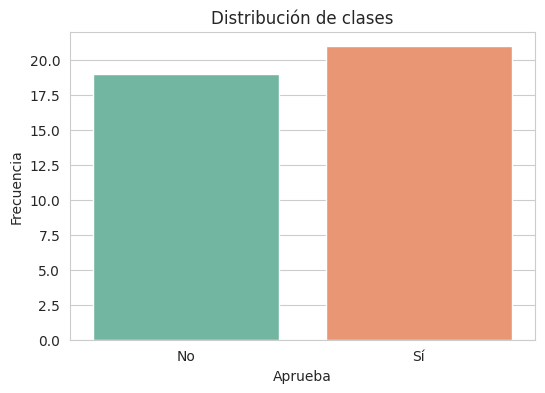

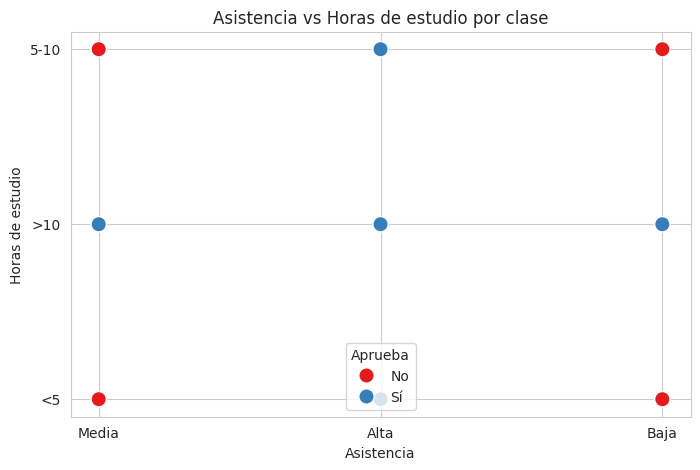

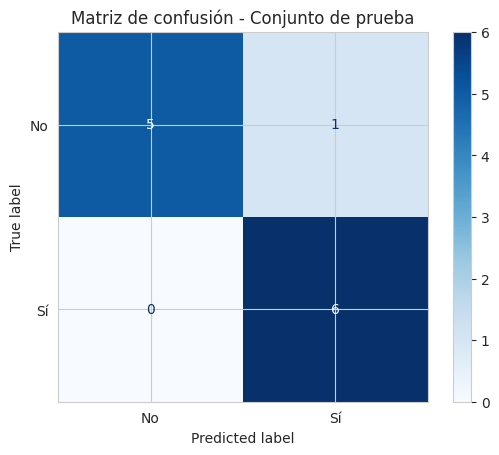

In [20]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Aprueba', hue='Aprueba', palette='Set2', legend=False)
plt.title('Distribución de clases')
plt.xlabel('Aprueba')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Asistencia', y='Horas_estudio', hue='Aprueba', s=120, palette='Set1')
plt.title('Asistencia vs Horas de estudio por clase')
plt.xlabel('Asistencia')
plt.ylabel('Horas de estudio')
plt.legend(title='Aprueba')
plt.show()

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder_y.classes_)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Conjunto de prueba')
plt.show()

## Conclusiones

- Naive Bayes es un algoritmo de clasificación supervisada rápido, sencillo e interpretable, basado en el teorema de Bayes.
- Asume independencia condicional entre las características dada la clase; es una simplificación fuerte, pero funcionó bien en este ejemplo.
- Se usó `CategoricalNB` porque las variables son categóricas (Asistencia, Horas_estudio, Trabaja).
- La validación cruzada eligió `alpha = 0.1`, que aplica un suavizado ligero y evita probabilidades cero sin borrar la información de las características.
- El modelo obtuvo **accuracy = 0.9167** en el conjunto de prueba (12 registros), mientras que predecir siempre la clase mayoritaria solo alcanzó **0.5000**. El modelo **supera claramente** la referencia.
- La matriz de confusión `[[5, 1], [0, 6]]` muestra que el modelo acertó 5 de 6 casos "No" y 6 de 6 casos "Sí"; solo falló en un caso "No" clasificado como "Sí".
- Las métricas por clase: para "Sí", precision = 0.86, recall = 1.00, F1 = 0.92; para "No", precision = 1.00, recall = 0.83, F1 = 0.91. El modelo es confiable en ambas clases.
- El caso nuevo (Asistencia = Alta, Horas_estudio = >10, Trabaja = No) fue clasificado como "Sí" con probabilidad 0.9998, lo cual es coherente con los patrones del dataset.
- Con solo 40 registros, los resultados son una demostración didáctica y no deben generalizarse a otros contextos. La elección de la semilla influye mucho en datasets pequeños.